<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/8a_suppl_code_FFNN_1dConv_RNN_keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Same as 8a but uses Keras instead of Pytorch
Pytorch is a longer code for defining NN architectures, it is good to use for beginners as it spells out every layer.

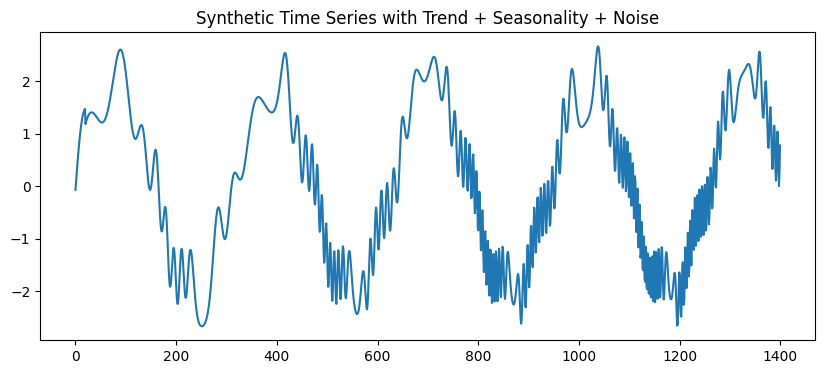

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training FFNN...

Training 1D CNN...

Training RNN (LSTM)...
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


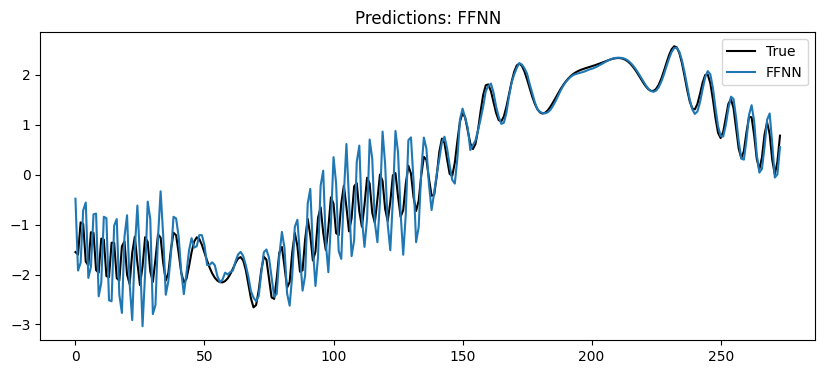

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


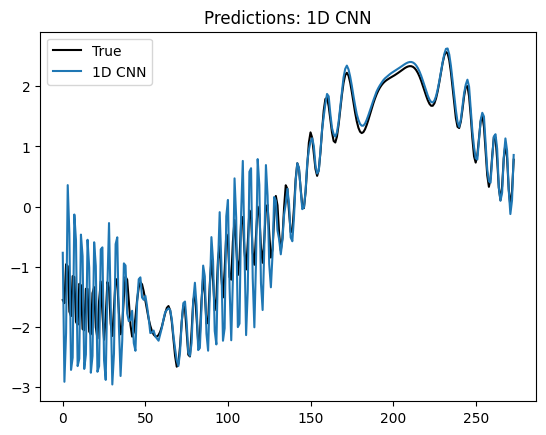

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


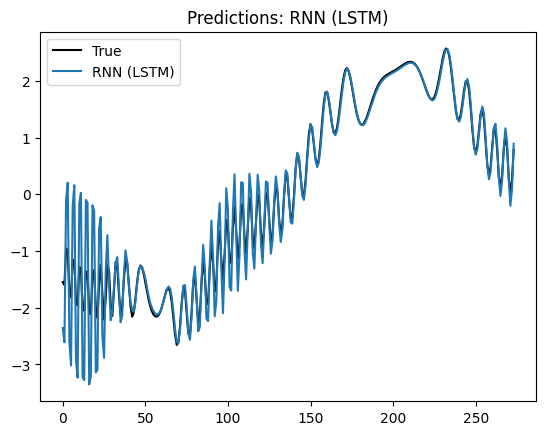

Comparison complete!
FFNN: Learns global relationships but may miss sequence order.
1D CNN: Detects local temporal patterns using convolution filters.
RNN (LSTM): Captures sequential dependencies and memory effects.


In [ ]:
# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, LSTM
from sklearn.preprocessing import MinMaxScaler

# --- 1. Generate Sample Time Series Data ---
#dataset 1
'''
np.random.seed(42)
time = np.arange(0, 1000, 1)
amplitude = 10 * np.sin(time / 10) + np.random.randn(len(time)) * 2
trend = 0.2 * time
data = amplitude + trend
'''

#datset 2
np.random.seed(42)
time = np.arange(0, 1400, 1)

# --- Components ---
# A slow varying baseline
slow_component = np.sin(time / 50)

# A faster oscillation modulated by the slow component
fast_component = np.sin(time / (5 + 3 * (slow_component + 1)))

# A delayed dependency (introduces memory)
delayed_component = np.roll(np.sin(time / 10), 20)

# Combine them with some nonlinearity and noise
data = 2 * slow_component + 0.5 * fast_component + 0.3 * delayed_component
#data += 0.1 * np.random.randn(len(time))  # noise

plt.figure(figsize=(10,4))
plt.plot(time, data)
plt.title("Synthetic Time Series with Trend + Seasonality + Noise")
plt.show()

# --- 2. Prepare Data for Supervised Learning ---
n_steps = 30  # how many past time points to use
X, y = [], []
for i in range(len(data) - n_steps):
    X.append(data[i:i+n_steps])
    y.append(data[i+n_steps])
X = np.array(X)
y = np.array(y)

# Scale data for stable training
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
y_scaled = scaler.fit_transform(y.reshape(-1,1))

# Split into train/test
split = int(len(X_scaled)*0.8)
X_train, X_test = X_scaled[:split], X_scaled[split:]
y_train, y_test = y_scaled[:split], y_scaled[split:]

# --- 3. Reshape for Different Model Types ---
X_train_ffnn = X_train
X_test_ffnn = X_test

# CNN and RNN expect 3D input: [samples, timesteps, features]
X_train_seq = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_seq = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# --- 4. Define Models ---
def build_ffnn():
    model = Sequential([
        Dense(64, activation='relu', input_shape=(n_steps,)),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def build_cnn():
    model = Sequential([
        Conv1D(32, kernel_size=3, activation='relu', input_shape=(n_steps,1)),
        Flatten(),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def build_rnn():
    model = Sequential([
        LSTM(64, activation='tanh', input_shape=(n_steps,1)),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

# --- 5. Train Models ---
models = {
    "FFNN": build_ffnn(),
    "1D CNN": build_cnn(),
    "RNN (LSTM)": build_rnn()
}

histories = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    history = model.fit(
        X_train_ffnn if name=="FFNN" else X_train_seq,
        y_train,
        epochs=50, batch_size=8, verbose=0,
        validation_split=0.1
    )
    histories[name] = history

# --- 6. Evaluate & Compare ---
plt.figure(figsize=(10,4))
for name, model in models.items():
    X_in = X_test_ffnn if name=="FFNN" else X_test_seq
    preds = model.predict(X_in)
    preds_rescaled = scaler.inverse_transform(preds)
    plt.plot(range(len(y_test)), scaler.inverse_transform(y_test), label='True', color='black')
    plt.plot(range(len(preds_rescaled)), preds_rescaled, label=name)
    plt.title(f"Predictions: {name}")
    plt.legend()
    plt.show()

# --- 7. Summary ---
print("Comparison complete!")
print("FFNN: Learns global relationships but may miss sequence order.")
print("1D CNN: Detects local temporal patterns using convolution filters.")
print("RNN (LSTM): Captures sequential dependencies and memory effects.")


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


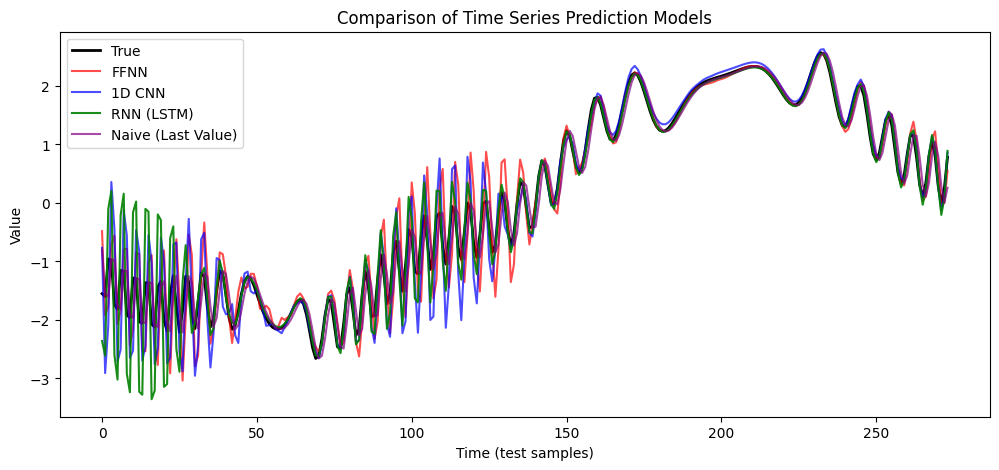

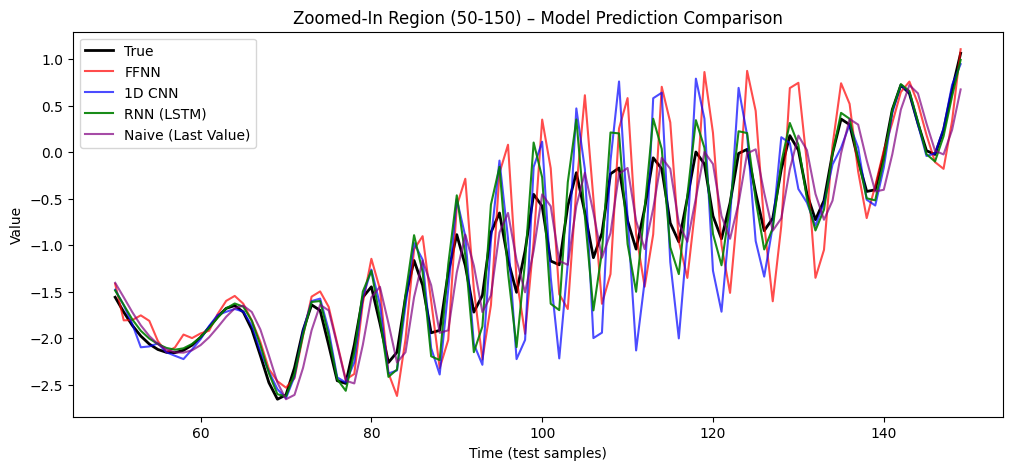


📈 Quantitative Comparison (lower RMSE and MAE are better, higher R² is better):

             Model     RMSE       R²      MAE
              FFNN 0.447295 0.919375 0.285493
            1D CNN 0.428539 0.925994 0.262255
        RNN (LSTM) 0.364863 0.946353 0.187026
Naive (Last Value) 0.306395 0.962169 0.234112


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import pandas as pd
import numpy as np

# --- 6. Evaluate, Plot, and Compute Metrics ---
plt.figure(figsize=(12,5))
y_true = scaler.inverse_transform(y_test.reshape(-1,1))

# Collect predictions
pred_dict = {}
metrics = {"Model": [], "RMSE": [], "R²": [], "MAE": []}

for name, model in models.items():
    X_in = X_test_ffnn if name=="FFNN" else X_test_seq
    preds = model.predict(X_in)
    preds_rescaled = scaler.inverse_transform(preds)
    pred_dict[name] = preds_rescaled

    # Compute metrics
    rmse = np.sqrt(mean_squared_error(y_true, preds_rescaled))
    r2 = r2_score(y_true, preds_rescaled)
    mae = mean_absolute_error(y_true, preds_rescaled)
    metrics["Model"].append(name)
    metrics["RMSE"].append(rmse)
    metrics["R²"].append(r2)
    metrics["MAE"].append(mae)

# Add naive method (tomorrow is same as today; value of t+1 = value of t)
naive_preds = scaler.inverse_transform(X_test[:, -1].reshape(-1, 1))
naive_rmse = np.sqrt(mean_squared_error(y_true, naive_preds))
naive_r2 = r2_score(y_true, naive_preds)
naive_mae = mean_absolute_error(y_true, naive_preds)

metrics["Model"].append("Naive (Last Value)")
metrics["RMSE"].append(naive_rmse)
metrics["R²"].append(naive_r2)
metrics["MAE"].append(naive_mae)
pred_dict["Naive (Last Value)"] = naive_preds


# --- Plot all predictions on one plot ---
plt.plot(range(len(y_true)), y_true, color='black', label='True', linewidth=2)
plt.plot(range(len(y_true)), pred_dict["FFNN"], label='FFNN', color='red', alpha=0.7)
plt.plot(range(len(y_true)), pred_dict["1D CNN"], label='1D CNN', color='blue', alpha=0.7)
plt.plot(range(len(y_true)), pred_dict["RNN (LSTM)"], label='RNN (LSTM)', color='green', alpha=0.9)
plt.plot(range(len(y_true)), pred_dict["Naive (Last Value)"], label='Naive (Last Value)', color='purple', alpha=0.7)


plt.title("Comparison of Time Series Prediction Models")
plt.xlabel("Time (test samples)")
plt.ylabel("Value")
plt.legend()
plt.show()

# --- Zoomed-in view ---
zoom_start_idx = 50
zoom_end_idx = min(zoom_start_idx + 100, len(y_true)) # Ensure zoom_end_idx does not exceed the length of y_true

plt.figure(figsize=(12,5))
plt.plot(range(zoom_start_idx, zoom_end_idx), y_true[zoom_start_idx:zoom_end_idx].flatten(), label='True', color='black', linewidth=2)
plt.plot(range(zoom_start_idx, zoom_end_idx), pred_dict["FFNN"][zoom_start_idx:zoom_end_idx].flatten(), label='FFNN', color='red', alpha=0.7)
plt.plot(range(zoom_start_idx, zoom_end_idx), pred_dict["1D CNN"][zoom_start_idx:zoom_end_idx].flatten(), label='1D CNN', color='blue', alpha=0.7)
plt.plot(range(zoom_start_idx, zoom_end_idx), pred_dict["RNN (LSTM)"][zoom_start_idx:zoom_end_idx].flatten(), label='RNN (LSTM)', color='green', alpha=0.9)
plt.plot(range(zoom_start_idx, zoom_end_idx), pred_dict["Naive (Last Value)"][zoom_start_idx:zoom_end_idx].flatten(), label='Naive (Last Value)', color='purple', alpha=0.7)

plt.title(f"Zoomed-In Region ({zoom_start_idx}-{zoom_end_idx}) – Model Prediction Comparison")
plt.xlabel("Time (test samples)")
plt.ylabel("Value")
plt.legend()
plt.show()


# --- 7. Print Metrics Summary ---
df_metrics = pd.DataFrame(metrics)
print("\n📈 Quantitative Comparison (lower RMSE and MAE are better, higher R² is better):\n")
print(df_metrics.to_string(index=False))